In [1]:
import os
import h5py
import lmdb
import torch
import pickle
import numpy as np
import matplotlib.pyplot as plt

datasets_settings_test = {
    'dw': {
        'data_path': '/p/project1/hai_dm4eo/liu_ch/data/SSL4EO-S2/downstream_lmdb_small_remove/dw_test_lmdb',
        'mode': 's2',
        'n_channels': 13,
    },

    'openearthmap': {
        'data_path': '/p/project1/hai_ws4eo/liu_ch/data/WeakFT/exact/openearthmap_val.lmdb',
    },
}

def calculate_iou(pred, gt, n_classes):
    ious = []
    for i in range(1,n_classes+1):
        pred_ = (pred == i).astype(float)   
        gt_ = (gt == i).astype(float)
        intersection = np.sum(pred_ * gt_)
        union = np.sum(pred_) + np.sum(gt_) - intersection
        iou = intersection / union
        ious.append(iou)
    return ious

In [2]:
from matplotlib.colors import ListedColormap

# color bar 
# (1) Water, (2) Trees, (3) Grass, (4) Flooded vegetation, 
# (5) Crops, (6) Shrub and scrub, (7) Built area, and (8) Bareland. (9) Ice and snow 
colors = [[255,255,255],
          [0,0,255],[0,130,59],[155,187,89],[153,204,255],[255,153,0],[68,1,84],
          [192,0,0],[253,231,36],[221,221,221], [0,0,0]]
colors = np.array(colors)/255
cmap_dw = ListedColormap(colors)

colors_oem = [[255,255,255],
              [253,231,36],[0,130,59],[192,0,0],[221,221,221],[0,130,59],[0,0,255],[255,153,0],[255, 255,0]]
colors_oem = np.array(colors_oem)/255
cmap_oem = ListedColormap(colors_oem)

# DW

ts_acc (1350, 10)
ts_acc_aux (1350, 10)
ts_acc_pred (1350, 10)
ts_acc_pred_ano (1350, 10)
ts_acc_pred_aux (1350, 10)
ts_acc_pred_aux_ano (1350, 10)
ts_exist (1350, 10)
ts_exist_aux (1350, 10)
ts_iou (1350, 10)
ts_iou_aux (1350, 10)
ts_iou_pred (1350, 10)
ts_iou_pred_ano (1350, 10)
ts_iou_pred_aux (1350, 10)
ts_iou_pred_aux_ano (1350, 10)
ts_masks (1350, 256, 256)
ts_masks_aux (1350, 256, 256)
y_exist (1350, 10)


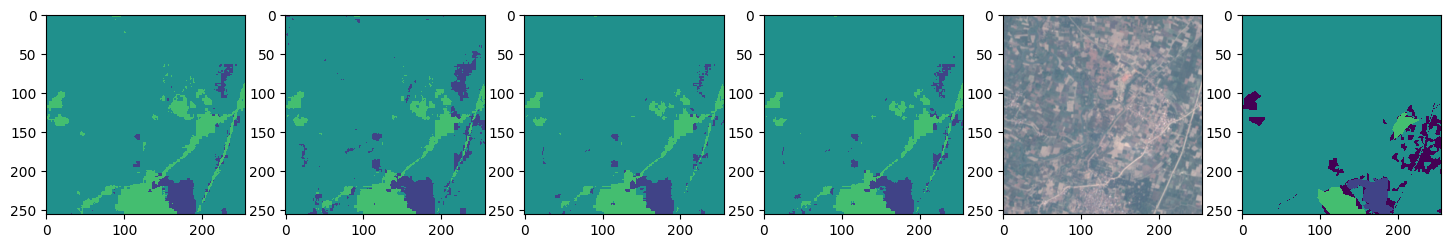

In [108]:
dataset_name = 'dw'
pdir = f'/p/project1/hai_ws4eo/liu_ch/Weak_FT/segment-anything-2/Results_1st_stage/FT_dofab_aux_exact_max15000_deI_mcloss/10F_1D_lr1e4_cos_w5_cos95/seed_42_bs_6/predictions_{dataset_name}'
index = 0

# gt & img
fp_test = datasets_settings_test[dataset_name]['data_path']
with lmdb.open(fp_test, readonly=True).begin(write=False) as txn:
    key_lbl = f'dw_{index}'
    data_lbl = txn.get(key_lbl.encode())
    lbl_bytes, lbl_shape, lbl_fid = pickle.loads(data_lbl)
    lbl = np.frombuffer(lbl_bytes, dtype=np.uint8).reshape(lbl_shape).copy()
    # image
    key_s = f's2_{index}'
    data_s = txn.get(key_s.encode())
    img_s, shape_s, fid_s = pickle.loads(data_s)
    img = np.frombuffer(img_s, dtype=np.uint16).reshape(shape_s)[[3,2,1]].astype(np.float32)
    img = img/img.max()

# illustration
plt.figure(figsize=(18, 3))
for ei, ep in enumerate([49, 59, 69, 79]):
    pred_fp = os.path.join(pdir, f'pred_EP{ep}.h5')
    with h5py.File(pred_fp, 'r') as f:
        if ei == 0: 
            for k in f.keys(): print(k, f[k].shape) 
        pred = f['ts_masks'][index]
    plt.subplot(1, 6, ei+1)
    plt.imshow(pred+1, interpolation='none', vmin=0, vmax=10)

plt.subplot(165)
plt.imshow(img.transpose(1,2,0))
plt.subplot(166)
plt.imshow(lbl, interpolation='none', vmin=0, vmax=10)

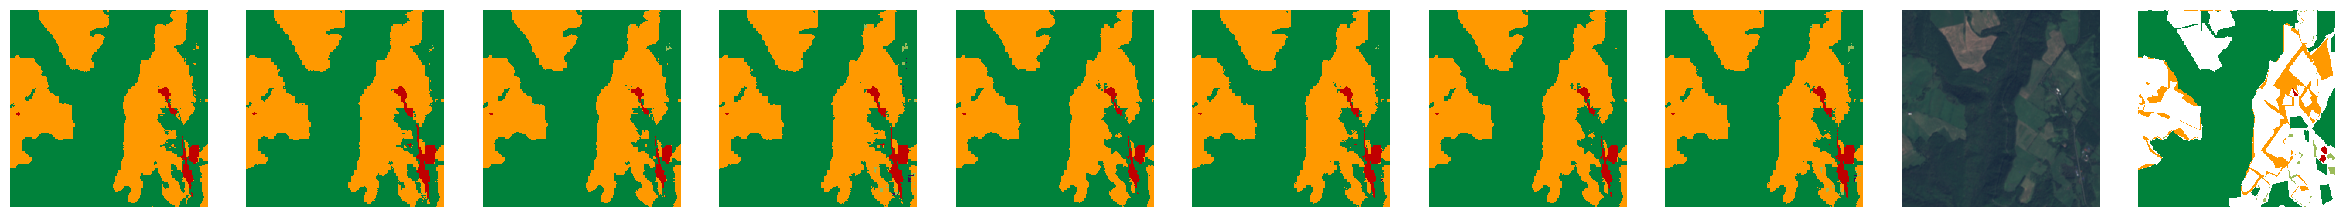

In [32]:
pdir = '/p/project1/hai_ws4eo/liu_ch/Weak_FT/segment-anything-2/Results_1st_stage/FT_dofab_aux_exact_max15000_deI_mcloss/10F_1D_lr1e4_cos_w5_cos95/seed_42_bs_6'
N = dw_show_images(pdir, index=13, eps=[49,59, 69,79])

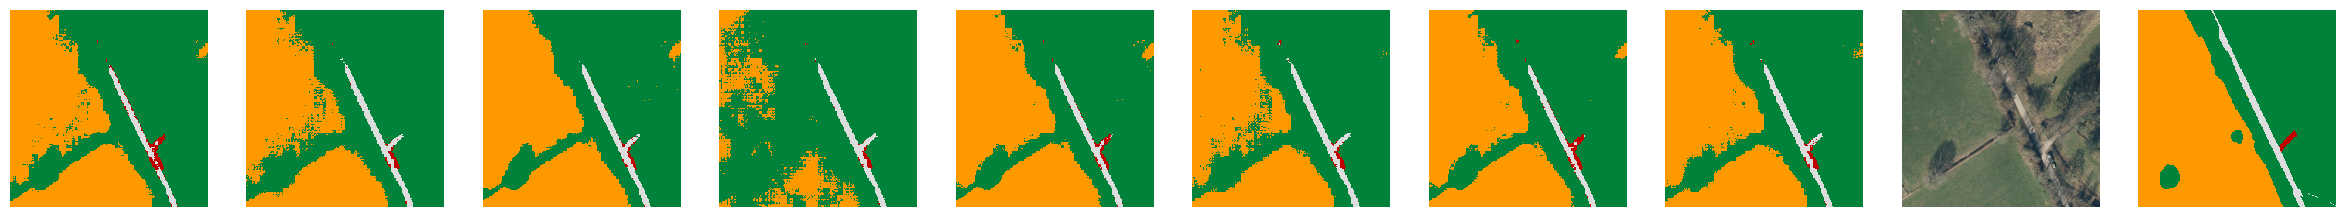

In [20]:
N = openearthmap_show_images(pdir, index=0, eps=[49,59,69, 79])

In [7]:
m = 'acc'
vs = {}
for ei, ep in enumerate([49, 59, 69, 79]):
    print(f'EP={ep}')
    pred_fp = os.path.join(pdir, f'pred_EP{ep}.h5')
    with h5py.File(pred_fp, 'r') as f:
        ts = f[f'ts_{m}'][()]
        pred = f[f'ts_{m}_pred'][()]
        pred_aux = f[f'ts_{m}_pred_aux'][()]
        pred_ano = f[f'ts_{m}_pred_ano'][()]
        pred_aux_ano = f[f'ts_{m}_pred_aux_ano'][()]
    print(f'{m:12s}', [f'{v:02f}' for v in ts.mean(axis=0)])
    for k, v in zip(['pred', 'pred_aux', 'pred_ano', 'pred_aux_ano'], [pred, pred_aux, pred_ano, pred_aux_ano]):
        print(f'{k:12s}', [f'{v0:02f}' for v0 in v.mean(axis=0)])
    # print('')
    # for k, v in zip(['pred', 'pred_aux', 'pred_ano', 'pred_aux_ano'], [pred, pred_aux, pred_ano, pred_aux_ano]):
    #     vs[k] = abs(v-ts).mean(axis=0)
    #     print(f'{k:12s}', [f'{v:02f}' for v in vs[k]])

EP=49
acc          ['0.744826', '0.638368', '0.779266', '0.767812', '0.723185', '0.475499', '0.608396', '0.619975', '0.915776', '0.916574']
pred         ['0.759766', '0.703613', '0.937988', '0.838379', '0.756836', '0.693359', '0.567871', '0.771973', '0.944336', '0.937500']
pred_aux     ['0.772949', '0.726562', '0.900879', '0.902344', '0.748535', '0.758301', '0.590820', '0.735840', '0.958496', '0.958984']
pred_ano     ['0.773438', '0.707031', '0.876465', '0.807129', '0.757324', '0.656250', '0.593750', '0.708984', '0.934082', '0.944824']
pred_aux_ano ['0.815430', '0.732422', '0.900391', '0.886230', '0.789551', '0.663574', '0.633789', '0.809570', '0.968262', '0.967285']
EP=59
acc          ['0.794973', '0.654204', '0.805902', '0.857271', '0.754624', '0.512787', '0.639025', '0.582674', '0.930041', '0.946965']
pred         ['0.788574', '0.712402', '0.933105', '0.873047', '0.758789', '0.717773', '0.583984', '0.696289', '0.949219', '0.951172']
pred_aux     ['0.739258', '0.750488', '0.842285', 

In [8]:
m = 'iou'
vs = {}
for ei, ep in enumerate([49, 59, 69, 79]):
    print(f'EP={ep}')
    pred_fp = os.path.join(pdir, f'pred_EP{ep}.h5')
    with h5py.File(pred_fp, 'r') as f:
        ts = f[f'ts_{m}'][()]
        pred = f[f'ts_{m}_pred'][()]
        pred_aux = f[f'ts_{m}_pred_aux'][()]
        pred_ano = f[f'ts_{m}_pred_ano'][()]
        pred_aux_ano = f[f'ts_{m}_pred_aux_ano'][()]
    print(f'{m:12s}', [f'{v:02f}' for v in ts.mean(axis=0)], np.mean(ts))
    for k, v in zip(['pred', 'pred_aux', 'pred_ano', 'pred_aux_ano'], [pred, pred_aux, pred_ano, pred_aux_ano]):
        print(f'{k:12s}', [f'{v0:02f}' for v0 in v.mean(axis=0)], np.mean(v))
    print('')
    for k, v in zip(['pred', 'pred_aux', 'pred_ano', 'pred_aux_ano'], [pred, pred_aux, pred_ano, pred_aux_ano]):
        vs[k] = abs(v-ts).mean(axis=0)
        print(f'{k:12s}', [f'{v:02f}' for v in vs[k]])

EP=49
iou          ['0.635238', '0.411763', '0.387287', '0.681403', '0.546905', '0.249280', '0.539410', '0.361058', '0.904711', '0.911150'] 0.56282055
pred         ['0.677246', '0.402832', '0.628906', '0.725098', '0.612793', '0.359131', '0.520996', '0.379150', '0.920410', '0.931152'] 0.6157
pred_aux     ['0.711914', '0.467529', '0.587402', '0.829590', '0.590332', '0.450684', '0.562988', '0.430176', '0.954590', '0.950684'] 0.6533
pred_ano     ['0.303223', '0.328369', '0.046326', '0.030533', '0.243164', '0.180664', '0.230835', '0.083801', '0.027588', '0.028000'] 0.1503
pred_aux_ano ['0.292969', '0.292236', '0.050842', '0.021286', '0.238525', '0.191040', '0.240112', '0.109619', '0.024551', '0.025421'] 0.1487

pred         ['0.172200', '0.217939', '0.376424', '0.161389', '0.191432', '0.255414', '0.124775', '0.244323', '0.043596', '0.038314']
pred_aux     ['0.191970', '0.240358', '0.367269', '0.209329', '0.215442', '0.329349', '0.152333', '0.284608', '0.066682', '0.064483']
pred_ano     ['0

In [109]:
# all the gt labels 
envt = lmdb.open(fp_test, max_readers=1, readonly=True, lock=False, readahead=False, meminit=False)
lbls = []
with envt.begin(write=False) as txn:
    for i in range(1350):
        key_lbl = f'dw_{i}'
        data_lbl = txn.get(key_lbl.encode())
        lbl_bytes, lbl_shape, lbl_fid = pickle.loads(data_lbl)
        lbl = np.frombuffer(lbl_bytes, dtype=np.uint8).reshape(lbl_shape).copy()
        lbl.setflags(write=True)
        lbls.append(lbl)

lbls = np.array(lbls)
print(lbls.shape)

(1350, 256, 256)


In [ ]:
ious_new = {}
for ei, ep in enumerate([49, 59, 69, 79]):
    print(f'EP={ep}')
    pred_fp = os.path.join(pdir, f'pred_EP{ep}.h5')
    with h5py.File(pred_fp, 'r') as f:
        masks = f[f'ts_masks'][()] 
        masks_aux = f[f'ts_masks_aux'][()]

    for m, k in zip([masks, masks_aux],['ts_masks', 'ts_masks_aux']):
        m += 1
        m[lbls==0] = 0
        ious_10 = calculate_iou(m, lbls, n_classes=10)
        ious_9  = calculate_iou(m, lbls, n_classes=9)
        ious_new[f'{ep}-{k}-9'] = ious_9 
        ious_new[f'{ep}-{k}-10'] = ious_10

ious_new

In [15]:
for k in ious_new.keys():
    ious_new[k] += [np.mean(ious_new[k])]
    print(f'{k:20s}', [f'{v:02f}' for v in ious_new[k]])

49-ts_masks-9        ['0.889770', '0.739465', '0.251535', '0.464660', '0.771952', '0.440662', '0.796638', '0.432964', '0.779317', '0.618551']
49-ts_masks-10       ['0.889770', '0.739465', '0.251535', '0.464660', '0.771952', '0.440662', '0.796638', '0.432964', '0.779317', '0.412528', '0.597949']
49-ts_masks_aux-9    ['0.883698', '0.716039', '0.241018', '0.488620', '0.765913', '0.411190', '0.801039', '0.427896', '0.830180', '0.618399']
49-ts_masks_aux-10   ['0.883698', '0.716039', '0.241018', '0.488620', '0.765913', '0.411190', '0.801039', '0.427896', '0.830180', '0.449679', '0.601527']
59-ts_masks-9        ['0.880315', '0.720698', '0.266640', '0.491653', '0.776549', '0.430034', '0.808351', '0.463386', '0.825156', '0.629198']
59-ts_masks-10       ['0.880315', '0.720698', '0.266640', '0.491653', '0.776549', '0.430034', '0.808351', '0.463386', '0.825156', '0.407899', '0.607068']
59-ts_masks_aux-9    ['0.906272', '0.712832', '0.251750', '0.479422', '0.765271', '0.413458', '0.806966', '0.486

In [110]:
mb = []
for c in range(1, 11):
    mb_ = (lbls==c).sum(axis=(1,2))>0
    mb.append(mb_)
mb = np.array(mb).T
mb.shape

(1350, 10)

Text(0, 0.5, 'Prediction')

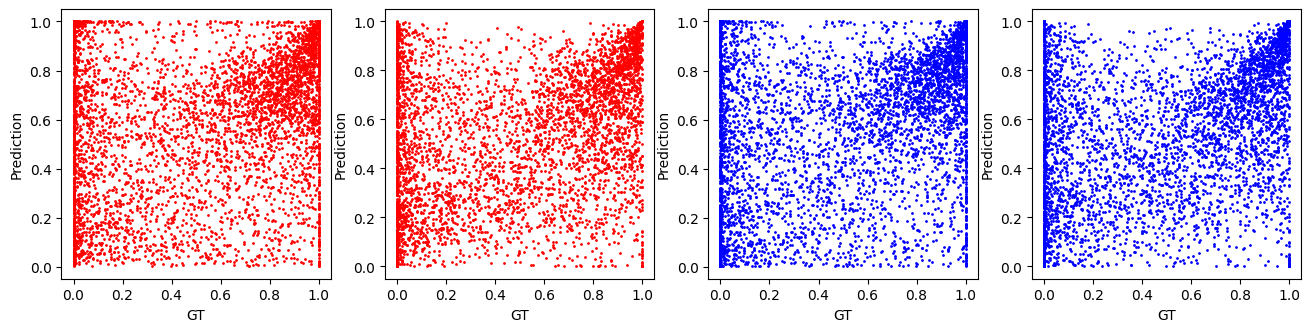

In [111]:
m = 'acc'
ep = 79
with h5py.File(pred_fp, 'r') as f:
    ts = f[f'ts_{m}'][()]
    ts_aux = f[f'ts_{m}_aux'][()]
    pred = f[f'ts_{m}_pred'][()]
    pred_aux = f[f'ts_{m}_pred_aux'][()]
    pred_ano = f[f'ts_{m}_pred_ano'][()]
    pred_aux_ano = f[f'ts_{m}_pred_aux_ano'][()]
plt.figure(figsize=(16, 3.5))
plt.subplot(141)
plt.plot(ts[mb], pred[mb], 'ro', markersize=1)
plt.xlabel('GT')
plt.ylabel('Prediction')
plt.subplot(142)
plt.plot(ts[mb], pred_ano[mb], 'ro', markersize=1)
plt.xlabel('GT')
plt.ylabel('Prediction')
plt.subplot(143)
plt.plot(ts_aux[mb], pred_aux[mb], 'bo', markersize=1)
plt.xlabel('GT')
plt.ylabel('Prediction')
plt.subplot(144)
plt.plot(ts_aux[mb], pred_aux_ano[mb], 'bo', markersize=1)
plt.xlabel('GT')
plt.ylabel('Prediction')

In [112]:
np.mean(abs(ts[mb]-pred_ano[mb])), np.mean(abs(ts_aux[mb]-pred_aux_ano[mb]))

(0.20938155, 0.20138049)

Text(0, 0.5, 'Prediction')

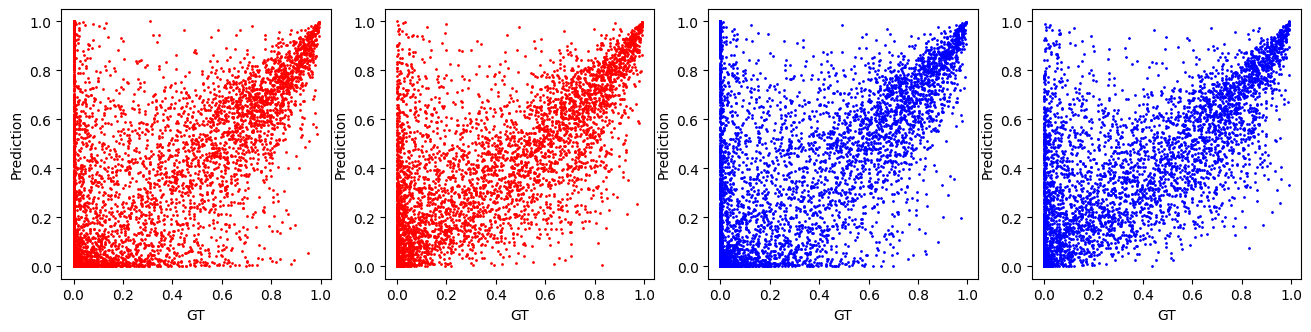

In [113]:
m = 'iou'
ep = 79
with h5py.File(pred_fp, 'r') as f:
    ts = f[f'ts_{m}'][()]
    ts_aux = f[f'ts_{m}_aux'][()]
    pred = f[f'ts_{m}_pred'][()]
    pred_aux = f[f'ts_{m}_pred_aux'][()]
    pred_ano = f[f'ts_{m}_pred_ano'][()]
    pred_aux_ano = f[f'ts_{m}_pred_aux_ano'][()]
plt.figure(figsize=(16, 3.5))
plt.subplot(141)
plt.plot(ts[mb], pred[mb], 'ro', markersize=1)
plt.xlabel('GT')
plt.ylabel('Prediction')
plt.subplot(142)
plt.plot(ts[mb], pred_ano[mb], 'ro', markersize=1)
plt.xlabel('GT')
plt.ylabel('Prediction')
plt.subplot(143)
plt.plot(ts_aux[mb], pred_aux[mb], 'bo', markersize=1)
plt.xlabel('GT')
plt.ylabel('Prediction')
plt.subplot(144)
plt.plot(ts_aux[mb], pred_aux_ano[mb], 'bo', markersize=1)
plt.xlabel('GT')
plt.ylabel('Prediction')

In [9]:
np.mean(abs(ts[mb]-pred_ano[mb])), np.mean(abs(ts_aux[mb]-pred_aux_ano[mb]))

(0.119777635, 0.117253825)

# OpenEarthNet

[2 3 4 5 8]


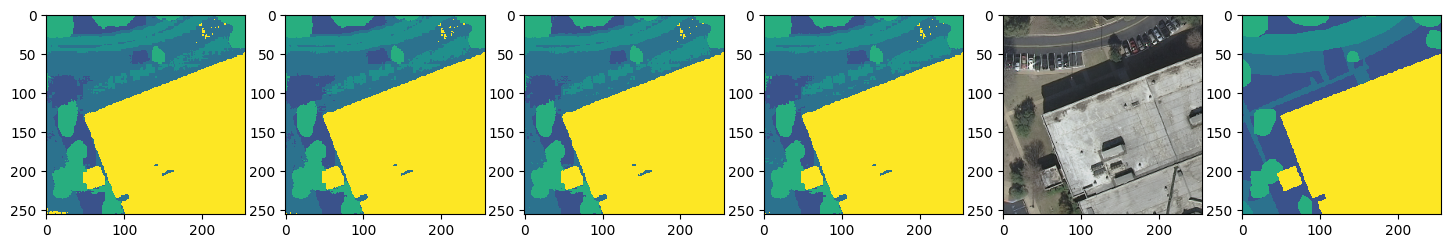

In [99]:
dataset_name = 'openearthmap'
pdir = f'/p/project1/hai_ws4eo/liu_ch/Weak_FT/segment-anything-2/Results_1st_stage/FT_dofab_aux_exact_max15000_deI_mcloss/10F_1D_lr1e4_cos_w5_cos95/seed_42_bs_6/predictions_{dataset_name}'
index = 310
n_cls = 8

# gt & img
fp_test = datasets_settings_test[dataset_name]['data_path']
with lmdb.open(fp_test, readonly=True).begin(write=False) as txn:
    key = str(index)
    data = txn.get(key.encode())
    data_bytes, data_shape, lbl_bytes, lbl_shape, a = pickle.loads(data)
    # print(data_shape, lbl_shape)
    img = np.frombuffer(data_bytes, dtype=np.uint8).reshape(data_shape)
    lbl = np.frombuffer(lbl_bytes, dtype=np.uint8).reshape(lbl_shape)
    
# illustration
plt.figure(figsize=(18, 3))
for ei, ep in enumerate([49, 59, 69, 79]):
    pred_fp = os.path.join(pdir, f'pred_EP{ep}.h5')
    with h5py.File(pred_fp, 'r') as f:
        # if ei == 0: 
        #     for k in f.keys(): print(k, f[k].shape) 
        pred = f['ts_masks'][index]
    plt.subplot(1, 6, ei+1)
    plt.imshow(pred+1, interpolation='none', vmin=0, vmax=n_cls)

plt.subplot(165)
plt.imshow(img.transpose(1,2,0))
plt.subplot(166)
plt.imshow(lbl, interpolation='none', vmin=0, vmax=n_cls)
print(np.unique(lbl))

In [21]:
m = 'acc'
vs = {}
for ei, ep in enumerate([49, 59, 69, 79]):
    print(f'EP={ep}')
    pred_fp = os.path.join(pdir, f'pred_EP{ep}.h5')
    with h5py.File(pred_fp, 'r') as f:
        ts = f[f'ts_{m}'][()]
        pred = f[f'ts_{m}_pred'][()]
        pred_aux = f[f'ts_{m}_pred_aux'][()]
        pred_ano = f[f'ts_{m}_pred_ano'][()]
        pred_aux_ano = f[f'ts_{m}_pred_aux_ano'][()]
    print(f'{m:12s}', [f'{v:02f}' for v in ts.mean(axis=0)], np.mean(ts))
    for k, v in zip(['pred', 'pred_aux', 'pred_ano', 'pred_aux_ano'], [pred, pred_aux, pred_ano, pred_aux_ano]):
        print(f'{k:12s}', [f'{v0:02f}' for v0 in v.mean(axis=0)], np.mean(v))
    print('')
    for k, v in zip(['pred', 'pred_aux', 'pred_ano', 'pred_aux_ano'], [pred, pred_aux, pred_ano, pred_aux_ano]):
        vs[k] = abs(v-ts).mean(axis=0)
        print(f'{k:12s}', [f'{v:02f}' for v in vs[k]], np.mean(vs[k]))

EP=49
acc          ['0.953294', '0.690570', '0.666054', '0.754758', '0.766745', '0.752312', '0.928162', '0.886002'] 0.7997366
pred         ['0.987305', '0.790039', '0.744629', '0.815918', '0.851562', '0.888184', '0.988281', '0.926758'] 0.874
pred_aux     ['0.983887', '0.783203', '0.734375', '0.817871', '0.836914', '0.827148', '0.984375', '0.916992'] 0.8604
pred_ano     ['0.987793', '0.755859', '0.714355', '0.840820', '0.814453', '0.849609', '0.985840', '0.914551'] 0.858
pred_aux_ano ['0.992676', '0.775879', '0.750488', '0.828125', '0.863770', '0.931152', '0.986816', '0.921387'] 0.8813

pred         ['0.039210', '0.193168', '0.177437', '0.160171', '0.141899', '0.178134', '0.068769', '0.076889'] 0.12945956
pred_aux     ['0.041874', '0.197448', '0.181415', '0.163620', '0.145172', '0.185434', '0.070127', '0.082727'] 0.13347712
pred_ano     ['0.036774', '0.176477', '0.154919', '0.154580', '0.126797', '0.121287', '0.067062', '0.076836'] 0.11434142
pred_aux_ano ['0.045214', '0.195797', '0.178

In [22]:
m = 'iou'
vs = {}
for ei, ep in enumerate([49, 59, 69, 79]):
    print(f'EP={ep}')
    pred_fp = os.path.join(pdir, f'pred_EP{ep}.h5')
    with h5py.File(pred_fp, 'r') as f:
        ts = f[f'ts_{m}'][()]
        pred = f[f'ts_{m}_pred'][()]
        pred_aux = f[f'ts_{m}_pred_aux'][()]
        pred_ano = f[f'ts_{m}_pred_ano'][()]
        pred_aux_ano = f[f'ts_{m}_pred_aux_ano'][()]
    print(f'{m:12s}', [f'{v:02f}' for v in ts.mean(axis=0)], np.mean(ts))
    for k, v in zip(['pred', 'pred_aux', 'pred_ano', 'pred_aux_ano'], [pred, pred_aux, pred_ano, pred_aux_ano]):
        print(f'{k:12s}', [f'{v0:02f}' for v0 in v.mean(axis=0)], np.mean(v))
    print('')
    for k, v in zip(['pred', 'pred_aux', 'pred_ano', 'pred_aux_ano'], [pred, pred_aux, pred_ano, pred_aux_ano]):
        vs[k] = abs(v-ts).mean(axis=0)
        print(f'{k:12s}', [f'{v:02f}' for v in vs[k]], np.mean(vs[k]))

EP=49
iou          ['0.919662', '0.452454', '0.465722', '0.587905', '0.612524', '0.691734', '0.844107', '0.780741'] 0.66935617
pred         ['0.949219', '0.478027', '0.451660', '0.598633', '0.648438', '0.768066', '0.876953', '0.807129'] 0.6973
pred_aux     ['0.948242', '0.458252', '0.437256', '0.596191', '0.615234', '0.777832', '0.853516', '0.795898'] 0.6855
pred_ano     ['0.017227', '0.403320', '0.311035', '0.393555', '0.562988', '0.133301', '0.182495', '0.539551'] 0.3179
pred_aux_ano ['0.018600', '0.428223', '0.307129', '0.369873', '0.551758', '0.124817', '0.182007', '0.542480'] 0.3157

pred         ['0.051510', '0.136300', '0.120778', '0.122704', '0.100186', '0.141322', '0.090926', '0.077410'] 0.10514183
pred_aux     ['0.063386', '0.140142', '0.126320', '0.134188', '0.107331', '0.187722', '0.107190', '0.086079'] 0.119044915
pred_ano     ['0.918209', '0.160712', '0.236016', '0.306060', '0.138306', '0.657040', '0.705365', '0.307529'] 0.42865467
pred_aux_ano ['0.919283', '0.171599', '0

In [100]:
# all the gt labels 
envt = lmdb.open(fp_test, max_readers=1, readonly=True, lock=False, readahead=False, meminit=False)
lbls = []
with envt.begin(write=False) as txn:
    for index in range(4270):
        key = str(index)
        data = txn.get(key.encode())
        data_bytes, data_shape, lbl_bytes, lbl_shape, a = pickle.loads(data)
        lbl = np.frombuffer(lbl_bytes, dtype=np.uint8).reshape(lbl_shape)#.copy()
        # lbl.setflags(write=True)
        lbls.append(lbl)

lbls = np.stack(lbls, axis=0)
print(lbls.shape)

(4270, 256, 256)


In [6]:
ious_new = {}
for ei, ep in enumerate([39, 49, 59, 69, 79]):
    print(f'EP={ep}')
    pred_fp = os.path.join(pdir, f'pred_EP{ep}.h5')
    with h5py.File(pred_fp, 'r') as f:
        masks = f[f'ts_masks'][()] 
        masks_aux = f[f'ts_masks_aux'][()]

    for m, k in zip([masks, masks_aux],['ts_masks', 'ts_masks_aux']):
        m += 1
        m[lbls==0] = 0
        ious_ = calculate_iou(m, lbls, n_classes=n_cls)
        ious_new[f'{ep}-{k}'] = ious_

for k in ious_new.keys():
    ious_new[k] += [np.mean(ious_new[k])]
    print(f'{k:20s}', [f'{v:02f}' for v in ious_new[k]])

EP=39
EP=49
EP=59
EP=69
EP=79
39-ts_masks          ['0.349432', '0.560153', '0.518606', '0.562604', '0.704489', '0.723196', '0.741461', '0.774563', '0.616813']
39-ts_masks_aux      ['0.343974', '0.554070', '0.510020', '0.552411', '0.704843', '0.720617', '0.745210', '0.766432', '0.612197']
49-ts_masks          ['0.366195', '0.559339', '0.529793', '0.558067', '0.712743', '0.721244', '0.750169', '0.775754', '0.621663']
49-ts_masks_aux      ['0.371055', '0.565107', '0.519410', '0.551284', '0.703704', '0.726615', '0.746079', '0.771742', '0.619374']
59-ts_masks          ['0.378385', '0.565150', '0.522665', '0.570366', '0.711225', '0.735414', '0.745784', '0.779050', '0.626005']
59-ts_masks_aux      ['0.373689', '0.570802', '0.527596', '0.554788', '0.703635', '0.731618', '0.743103', '0.775373', '0.622575']
69-ts_masks          ['0.394210', '0.565709', '0.531039', '0.570881', '0.713529', '0.742082', '0.750437', '0.779999', '0.630986']
69-ts_masks_aux      ['0.381410', '0.568587', '0.526547', '0

In [101]:
mb = []
for c in range(1, 9):
    mb_ = (lbls==c).sum(axis=(1,2))>0
    mb.append(mb_)
mb = np.array(mb).T
mb.shape

(4270, 8)

Text(0, 0.5, 'Prediction')

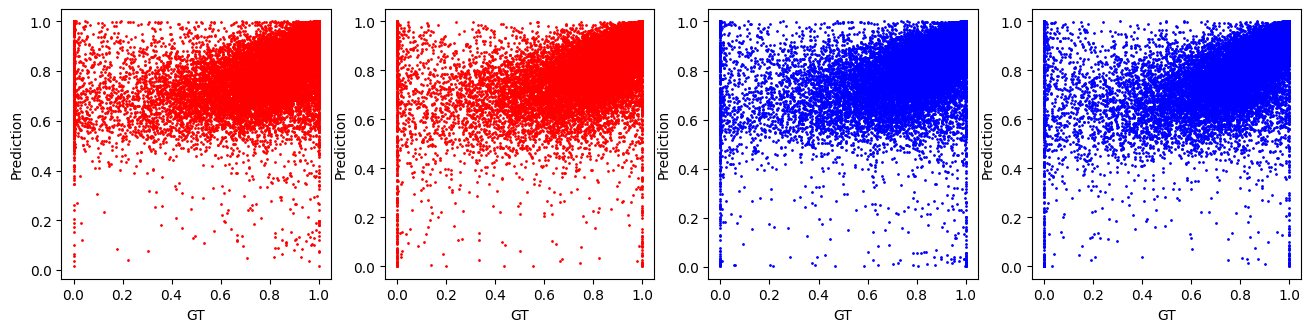

In [106]:
m = 'acc'
ep = 79
with h5py.File(pred_fp, 'r') as f:
    ts = f[f'ts_{m}'][()]
    ts_aux = f[f'ts_{m}_aux'][()]
    pred = f[f'ts_{m}_pred'][()]
    pred_aux = f[f'ts_{m}_pred_aux'][()]
    pred_ano = f[f'ts_{m}_pred_ano'][()]
    pred_aux_ano = f[f'ts_{m}_pred_aux_ano'][()]
plt.figure(figsize=(16, 3.5))
plt.subplot(141)
plt.plot(ts[mb], pred[mb], 'ro', markersize=1)
plt.xlabel('GT')
plt.ylabel('Prediction')
plt.subplot(142)
plt.plot(ts[mb], pred_ano[mb], 'ro', markersize=1)
plt.xlabel('GT')
plt.ylabel('Prediction')
plt.subplot(143)
plt.plot(ts_aux[mb], pred_aux[mb], 'bo', markersize=1)
plt.xlabel('GT')
plt.ylabel('Prediction')
plt.subplot(144)
plt.plot(ts_aux[mb], pred_aux_ano[mb], 'bo', markersize=1)
plt.xlabel('GT')
plt.ylabel('Prediction')

Text(0, 0.5, 'Prediction')

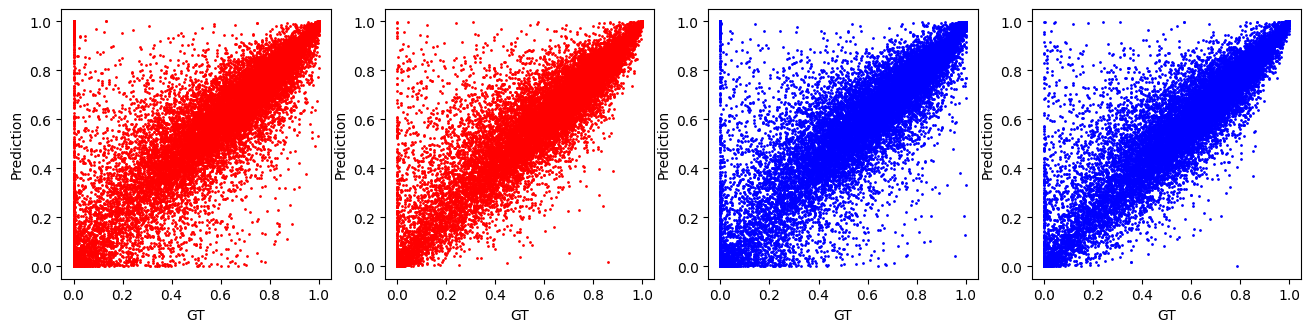

In [107]:
m = 'iou'
ep = 79
with h5py.File(pred_fp, 'r') as f:
    ts = f[f'ts_{m}'][()]
    ts_aux = f[f'ts_{m}_aux'][()]
    pred = f[f'ts_{m}_pred'][()]
    pred_aux = f[f'ts_{m}_pred_aux'][()]
    pred_ano = f[f'ts_{m}_pred_ano'][()]
    pred_aux_ano = f[f'ts_{m}_pred_aux_ano'][()]
plt.figure(figsize=(16, 3.5))
plt.subplot(141)
plt.plot(ts[mb], pred[mb], 'ro', markersize=1)
plt.xlabel('GT')
plt.ylabel('Prediction')
plt.subplot(142)
plt.plot(ts[mb], pred_ano[mb], 'ro', markersize=1)
plt.xlabel('GT')
plt.ylabel('Prediction')
plt.subplot(143)
plt.plot(ts_aux[mb], pred_aux[mb], 'bo', markersize=1)
plt.xlabel('GT')
plt.ylabel('Prediction')
plt.subplot(144)
plt.plot(ts_aux[mb], pred_aux_ano[mb], 'bo', markersize=1)
plt.xlabel('GT')
plt.ylabel('Prediction')

# Test on subsets

## Funtions

- DW

In [3]:
def dw_show_images(pdir, index=0, eps=[49, 59]):
    dataset_name = 'dw'
    pdir = os.path.join(pdir, f'predictions_{dataset_name}')

    # gt & img
    fp_test = datasets_settings_test[dataset_name]['data_path']
    with lmdb.open(fp_test, readonly=True).begin(write=False) as txn:
        key_lbl = f'dw_{index}'
        data_lbl = txn.get(key_lbl.encode())
        lbl_bytes, lbl_shape, lbl_fid = pickle.loads(data_lbl)
        lbl = np.frombuffer(lbl_bytes, dtype=np.uint8).reshape(lbl_shape).copy()
        # image
        key_s = f's2_{index}'
        data_s = txn.get(key_s.encode())
        img_s, shape_s, fid_s = pickle.loads(data_s)
        img = np.frombuffer(img_s, dtype=np.uint16).reshape(shape_s)[[3,2,1]].astype(np.float32)
        img = img/img.max()

    # illustration
    n = len(eps)*2+2
    plt.figure(figsize=(3*n, 3))
    for ei, ep in enumerate(eps):
        pred_fp = os.path.join(pdir, f'pred_EP{ep}.h5')
        with h5py.File(pred_fp, 'r') as f:
            if ei == 0: 
                # for k in f.keys(): print(k, f[k].shape) 
                N = f['ts_masks'].shape[0]
            pred = f['ts_masks'][index]
            pred_aux = f['ts_masks_aux'][index]
        plt.subplot(1, n, ei*2+1)
        plt.imshow(pred+1, interpolation='none', cmap=cmap_dw, vmin=0, vmax=10)
        plt.axis('off')
        plt.subplot(1, n, ei*2+2)
        plt.imshow(pred_aux+1, interpolation='none', cmap=cmap_dw, vmin=0, vmax=10)
        plt.axis('off')

    plt.subplot(1,n,n-1)
    plt.imshow(img.transpose(1,2,0))
    plt.axis('off')
    plt.subplot(1,n,n)
    plt.imshow(lbl, interpolation='none', cmap=cmap_dw, vmin=0, vmax=10)
    plt.axis('off')

    return N


# all the gt labels 
def dw_get_ious(pdir, N, eps=[49, 59]):
    dataset_name = 'dw'
    pdir = os.path.join(pdir, f'predictions_{dataset_name}')
    fp_test = datasets_settings_test[dataset_name]['data_path']
    envt = lmdb.open(fp_test, max_readers=1, readonly=True, lock=False, readahead=False, meminit=False)
    lbls = []
    with envt.begin(write=False) as txn:
        for i in range(N):
            key_lbl = f'dw_{i}'
            data_lbl = txn.get(key_lbl.encode())
            lbl_bytes, lbl_shape, lbl_fid = pickle.loads(data_lbl)
            lbl = np.frombuffer(lbl_bytes, dtype=np.uint8).reshape(lbl_shape).copy()
            lbl.setflags(write=True)
            lbls.append(lbl)

    lbls = np.array(lbls)
    print(lbls.shape)

    ious_new = {}
    for ei, ep in enumerate(eps):
        print(f'EP={ep}')
        pred_fp = os.path.join(pdir, f'pred_EP{ep}.h5')
        with h5py.File(pred_fp, 'r') as f:
            masks = f[f'ts_masks'][()] 
            masks_aux = f[f'ts_masks_aux'][()]

        for m, k in zip([masks, masks_aux],['ts_masks', 'ts_masks_aux']):
            m += 1
            m[lbls==0] = 0
            ious_10 = calculate_iou(m, lbls, n_classes=10)
            ious_9  = calculate_iou(m, lbls, n_classes=9)
            ious_new[f'{ep}-{k}-9'] = ious_9 
            ious_new[f'{ep}-{k}-10'] = ious_10

    for k in ious_new.keys():
        ious_new[k] += [np.mean(ious_new[k])]
        print(f'{k:20s}', [f'{v:02f}' for v in ious_new[k][:-1]], ious_new[k][-1])
    
    return ious_new

- OpenEarthMap

In [4]:
def openearthmap_show_images(pdir, index=0, eps=[49, 59]):
    dataset_name = 'openearthmap'
    pdir = os.path.join(pdir, f'predictions_{dataset_name}')
    n_cls = 8

    # gt & img
    fp_test = datasets_settings_test[dataset_name]['data_path']
    with lmdb.open(fp_test, readonly=True).begin(write=False) as txn:
        key = str(index)
        data = txn.get(key.encode())
        data_bytes, data_shape, lbl_bytes, lbl_shape, a = pickle.loads(data)
        # print(data_shape, lbl_shape)
        img = np.frombuffer(data_bytes, dtype=np.uint8).reshape(data_shape)
        lbl = np.frombuffer(lbl_bytes, dtype=np.uint8).reshape(lbl_shape)
        
    # illustration
    n = len(eps)*2+2
    plt.figure(figsize=(n*3, 3))
    for ei, ep in enumerate(eps):
        pred_fp = os.path.join(pdir, f'pred_EP{ep}.h5')
        with h5py.File(pred_fp, 'r') as f:
            if ei == 0: 
                N = f['ts_masks'].shape[0] 
            pred = f['ts_masks'][index]
            pred_aux = f['ts_masks_aux'][index]
        plt.subplot(1, n, ei*2+1)
        plt.imshow(pred+1, interpolation='none', cmap=cmap_oem, vmin=0, vmax=n_cls)
        plt.axis('off')
        plt.subplot(1, n, ei*2+2)
        plt.imshow(pred_aux+1, interpolation='none', cmap=cmap_oem, vmin=0, vmax=n_cls)
        plt.axis('off')

    plt.subplot(1,n,n-1)
    plt.imshow(img.transpose(1,2,0))
    plt.axis('off')
    plt.subplot(1,n,n)
    plt.imshow(lbl, interpolation='none', cmap=cmap_oem, vmin=0, vmax=n_cls)
    plt.axis('off')
    
    return N


def openearthmap_get_ious(pdir, N, eps=[49, 59]):
    dataset_name = 'openearthmap'
    pdir = os.path.join(pdir, f'predictions_{dataset_name}')
    fp_test = datasets_settings_test[dataset_name]['data_path']
    n_cls = 8
    # all the gt labels 
    envt = lmdb.open(fp_test, max_readers=1, readonly=True, lock=False, readahead=False, meminit=False)
    lbls = []
    with envt.begin(write=False) as txn:
        for index in range(N):
            key = str(index)
            data = txn.get(key.encode())
            data_bytes, data_shape, lbl_bytes, lbl_shape, a = pickle.loads(data)
            lbl = np.frombuffer(lbl_bytes, dtype=np.uint8).reshape(lbl_shape)#.copy()
            # lbl.setflags(write=True)
            lbls.append(lbl)

    lbls = np.array(lbls)
    print(lbls.shape)

    ious_new = {}
    for ei, ep in enumerate(eps):
        print(f'EP={ep}')
        pred_fp = os.path.join(pdir, f'pred_EP{ep}.h5')
        with h5py.File(pred_fp, 'r') as f:
            masks = f[f'ts_masks'][()] 
            masks_aux = f[f'ts_masks_aux'][()]

        for m, k in zip([masks, masks_aux],['ts_masks', 'ts_masks_aux']):
            m += 1
            m[lbls==0] = 0
            ious_ = calculate_iou(m, lbls, n_classes=n_cls)
            ious_new[f'{ep}-{k}'] = ious_ 

    for k in ious_new.keys():
        ious_new[k] += [np.mean(ious_new[k])]
        print(f'{k:20s}', [f'{v:02f}' for v in ious_new[k][:-1]], ious_new[k][-1])
    
    return ious_new
        

## 1. wo adapter

(1359, 256, 256)
EP=49
EP=59
49-ts_masks-9        ['0.784031', '0.618254', '0.022920', '0.038394', '0.582910', '0.323640', '0.648677', '0.357835', '0.746732'] 0.4581548413304994
49-ts_masks-10       ['0.784031', '0.618254', '0.022920', '0.038394', '0.582910', '0.323640', '0.648677', '0.357835', '0.746732', '0.264570'] 0.43879633605295226
49-ts_masks_aux-9    ['0.722830', '0.599710', '0.077072', '0.156136', '0.559039', '0.319485', '0.539088', '0.307875', '0.681036'] 0.44025230929432924
49-ts_masks_aux-10   ['0.722830', '0.599710', '0.077072', '0.156136', '0.559039', '0.319485', '0.539088', '0.307875', '0.681036', '0.152733'] 0.41150040451932723
59-ts_masks-9        ['0.804862', '0.634736', '0.039786', '0.193737', '0.633716', '0.364964', '0.645906', '0.346805', '0.755334'] 0.4910941722663925
59-ts_masks-10       ['0.804862', '0.634736', '0.039786', '0.193737', '0.633716', '0.364964', '0.645906', '0.346805', '0.755334', '0.262044'] 0.4681891669416281
59-ts_masks_aux-9    ['0.741773', '0.6

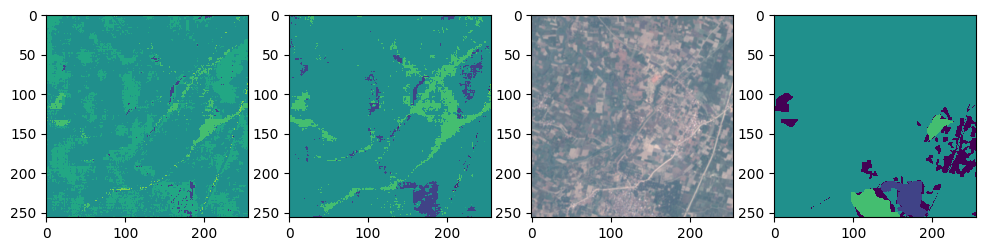

In [28]:
pdir1 = '/p/project1/hai_ws4eo/liu_ch/Weak_FT/segment-anything-2/Results_1st_stage_sub/FT_aux_woAd_exact_sub_max1500_deI_mcloss/10F_1D_lr1e4_cos_w5_cos95/seed_42_bs_6'
N = dw_show_images(pdir1, index=0, eps=[49, 59])
ious_woAd_dw = dw_get_ious(pdir1, N, eps=[49, 59])

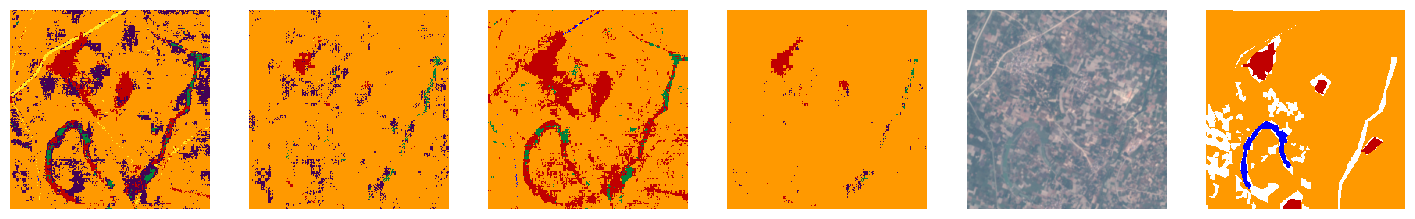

In [5]:
pdir1 = '/p/project1/hai_ws4eo/liu_ch/Weak_FT/segment-anything-2/Results_1st_stage_sub/FT_aux_woAd_exact_sub_max1500_deI_mcloss/10F_1D_lr1e4_cos_w5_cos95/seed_42_bs_6'
N = dw_show_images(pdir1, index=1, eps=[49, 59])

[2 3 4 5 7]
(4275, 256, 256)
EP=49
EP=59
49-ts_masks          ['0.141473', '0.428955', '0.400160', '0.437513', '0.629608', '0.457198', '0.582501', '0.662899'] 0.4675384234238462
49-ts_masks_aux      ['0.129167', '0.434079', '0.390696', '0.356803', '0.611317', '0.470532', '0.553579', '0.616639'] 0.445351444194042
59-ts_masks          ['0.078217', '0.455855', '0.398447', '0.440440', '0.640170', '0.520960', '0.599638', '0.665063'] 0.4748486503550613
59-ts_masks_aux      ['0.129558', '0.402706', '0.391666', '0.396897', '0.633490', '0.507897', '0.563500', '0.647302'] 0.4591273008891235


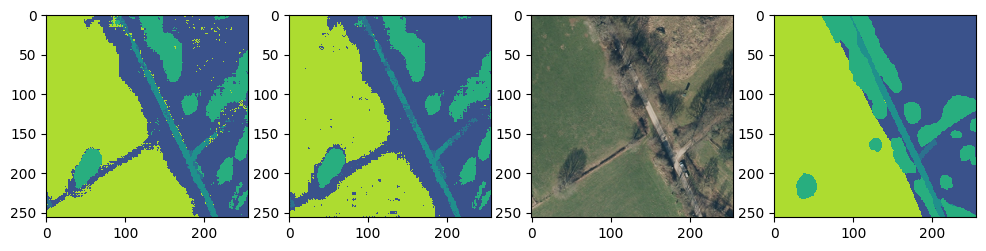

In [31]:
N = openearthmap_show_images(pdir1, index=0, eps=[49, 59])
ious_woAd_oem = openearthmap_get_ious(pdir1, N, eps=[49, 59])

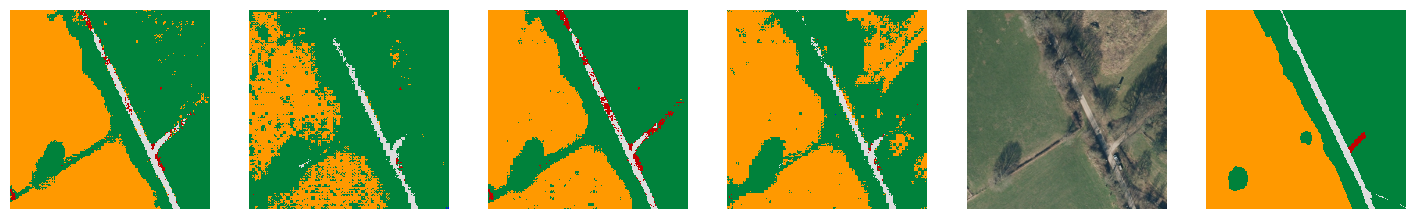

In [53]:
N = openearthmap_show_images(pdir1, index=0, eps=[49, 59])

## 2. w adaptor wo dofa

(1359, 256, 256)
EP=49
EP=59
49-ts_masks-9        ['0.826077', '0.699908', '0.074574', '0.369568', '0.675479', '0.377440', '0.764034', '0.323231', '0.801684'] 0.5457772258411916
49-ts_masks-10       ['0.826077', '0.699908', '0.074574', '0.369568', '0.675479', '0.377440', '0.764034', '0.323231', '0.801684', '0.287488'] 0.5199482627186087
49-ts_masks_aux-9    ['0.833757', '0.701687', '0.151948', '0.302957', '0.676879', '0.384036', '0.753901', '0.366252', '0.743804'] 0.5461356566048656
49-ts_masks_aux-10   ['0.833757', '0.701687', '0.151948', '0.302957', '0.676879', '0.384036', '0.753901', '0.366252', '0.743804', '0.207187'] 0.5122408276187611
59-ts_masks-9        ['0.849175', '0.715463', '0.139607', '0.349231', '0.726072', '0.386297', '0.776700', '0.306703', '0.781216'] 0.5589405347688863
59-ts_masks-10       ['0.849175', '0.715463', '0.139607', '0.349231', '0.726072', '0.386297', '0.776700', '0.306703', '0.781216', '0.263593'] 0.529405830419311
59-ts_masks_aux-9    ['0.846529', '0.70194

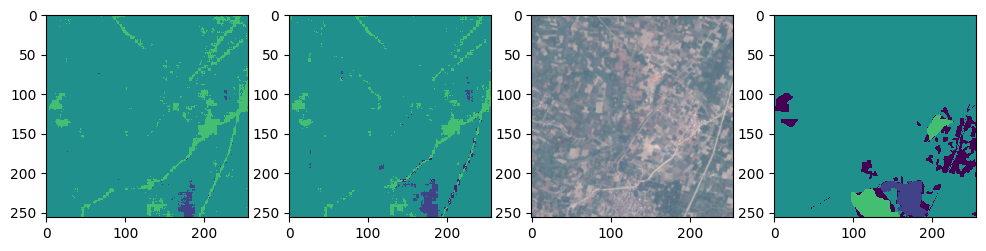

In [29]:
pdir2 = '/p/project1/hai_ws4eo/liu_ch/Weak_FT/segment-anything-2/Results_1st_stage_sub/FT_aux_exact_sub_max1500_deI_mcloss/10F_1D_lr1e4_cos_w5_cos95/seed_42_bs_6'
N = dw_show_images(pdir2, index=0, eps=[49, 59])
ious_wodofa_dw = dw_get_ious(pdir2, N, eps=[49, 59])

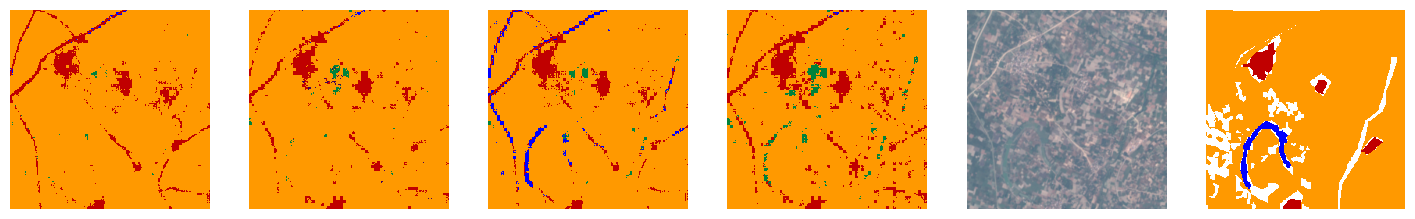

In [6]:
pdir2 = '/p/project1/hai_ws4eo/liu_ch/Weak_FT/segment-anything-2/Results_1st_stage_sub/FT_aux_exact_sub_max1500_deI_mcloss/10F_1D_lr1e4_cos_w5_cos95/seed_42_bs_6'
N = dw_show_images(pdir2, index=1, eps=[49, 59])

[2 3 4 5 7]
(4275, 256, 256)
EP=49
EP=59
49-ts_masks          ['0.283185', '0.473799', '0.452884', '0.456139', '0.671887', '0.608934', '0.640397', '0.718963'] 0.5382734582622517
49-ts_masks_aux      ['0.238982', '0.489770', '0.442516', '0.414387', '0.662009', '0.550530', '0.617036', '0.699683'] 0.5143641268118408
59-ts_masks          ['0.160919', '0.476633', '0.431272', '0.488144', '0.673931', '0.613350', '0.633101', '0.712307'] 0.5237072419322004
59-ts_masks_aux      ['0.181737', '0.476783', '0.433376', '0.463472', '0.663972', '0.591152', '0.632964', '0.710098'] 0.5191942507578078


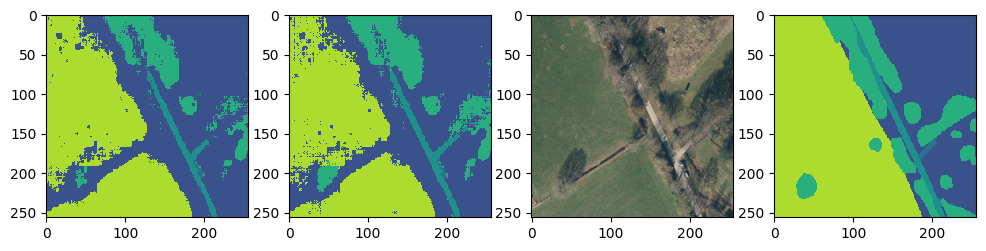

In [30]:
N = openearthmap_show_images(pdir2, index=0, eps=[49, 59])
ious_woAd_oem = openearthmap_get_ious(pdir2, N, eps=[49, 59])

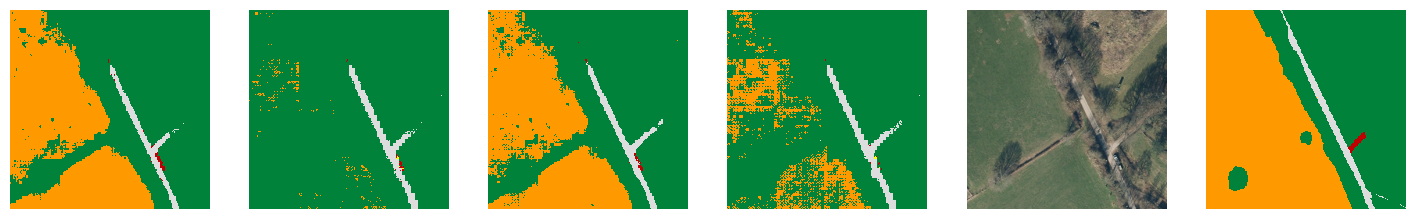

In [54]:
pdir2 = '/p/project1/hai_ws4eo/liu_ch/Weak_FT/segment-anything-2/Results_1st_stage_sub/FT_aux_exact_sub_max1500_deI_mcloss/10F_1D_lr1e4_cos_w5_cos95/seed_42_bs_6'
N = openearthmap_show_images(pdir2, index=0, eps=[49, 59])

## 3. w adaptor and dofa

(1359, 256, 256)
EP=49
EP=59
49-ts_masks-9        ['0.882625', '0.707391', '0.156238', '0.381556', '0.696585', '0.396629', '0.787234', '0.376626', '0.754053'] 0.5709929273951886
49-ts_masks-10       ['0.882625', '0.707391', '0.156238', '0.381556', '0.696585', '0.396629', '0.787234', '0.376626', '0.754053', '0.214438'] 0.5353374570628635
49-ts_masks_aux-9    ['0.862611', '0.714006', '0.146266', '0.371755', '0.675333', '0.396557', '0.759176', '0.405994', '0.731052'] 0.5625276894990715
49-ts_masks_aux-10   ['0.862611', '0.714006', '0.146266', '0.371755', '0.675333', '0.396557', '0.759176', '0.405994', '0.731052', '0.186733'] 0.5249481834230119
59-ts_masks-9        ['0.885095', '0.731176', '0.166000', '0.365114', '0.672680', '0.372895', '0.775036', '0.346068', '0.790479'] 0.5671715737681278
59-ts_masks-10       ['0.885095', '0.731176', '0.166000', '0.365114', '0.672680', '0.372895', '0.775036', '0.346068', '0.790479', '0.292084'] 0.5396627901230333
59-ts_masks_aux-9    ['0.871751', '0.7083

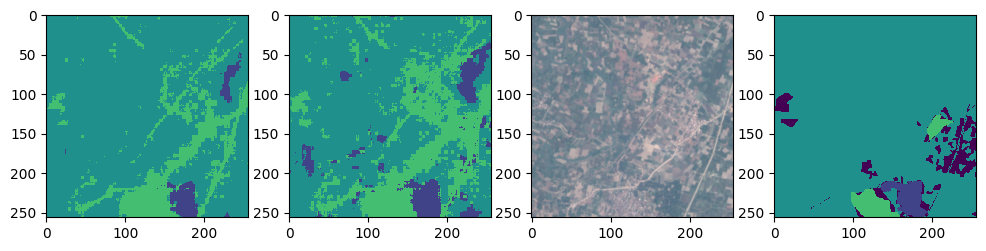

In [5]:
pdir3 = '/p/project1/hai_ws4eo/liu_ch/Weak_FT/segment-anything-2/Results_1st_stage_sub/FT_dofab_aux_exact_sub_max1500_deI_mcloss/10F_1D_lr1e4_cos_w5_cos95/seed_42_bs_6'
N = dw_show_images(pdir3, index=0, eps=[49, 59])
ious_dw = dw_get_ious(pdir3, N, eps=[49, 59])

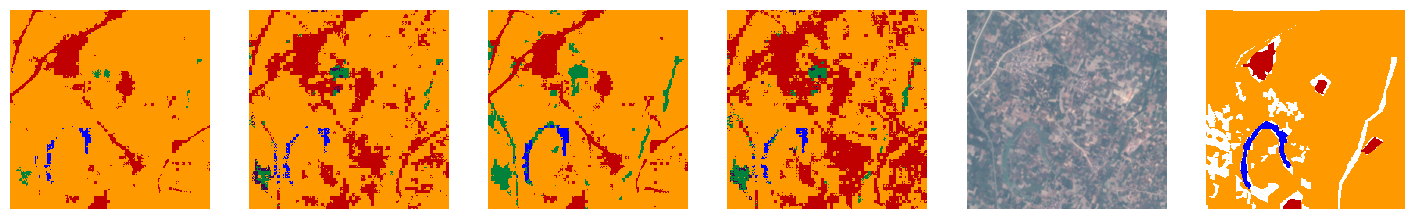

In [7]:
pdir3 = '/p/project1/hai_ws4eo/liu_ch/Weak_FT/segment-anything-2/Results_1st_stage_sub/FT_dofab_aux_exact_sub_max1500_deI_mcloss/10F_1D_lr1e4_cos_w5_cos95/seed_42_bs_6'
N = dw_show_images(pdir3, index=1, eps=[49, 59])

[2 3 4 5 8]
(4275, 256, 256)
EP=49
EP=59
49-ts_masks          ['0.239002', '0.497461', '0.464878', '0.499250', '0.676963', '0.591769', '0.680343', '0.739293'] 0.5486199138084318
49-ts_masks_aux      ['0.241229', '0.495385', '0.462238', '0.456888', '0.661111', '0.607418', '0.674154', '0.722234'] 0.5400822401875481
59-ts_masks          ['0.215128', '0.518648', '0.478463', '0.498117', '0.680199', '0.632029', '0.678314', '0.742854'] 0.5554689151529
59-ts_masks_aux      ['0.234512', '0.498585', '0.470727', '0.453016', '0.677028', '0.613269', '0.687243', '0.725070'] 0.5449313527543329


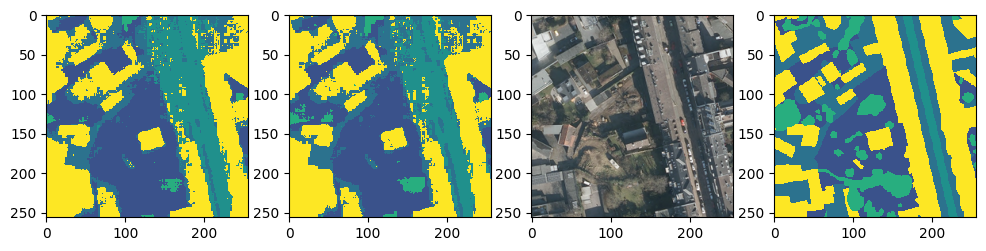

In [9]:
N = openearthmap_show_images(pdir3, index=10, eps=[49, 59])
ious_oem = openearthmap_get_ious(pdir3, N, eps=[49, 59])

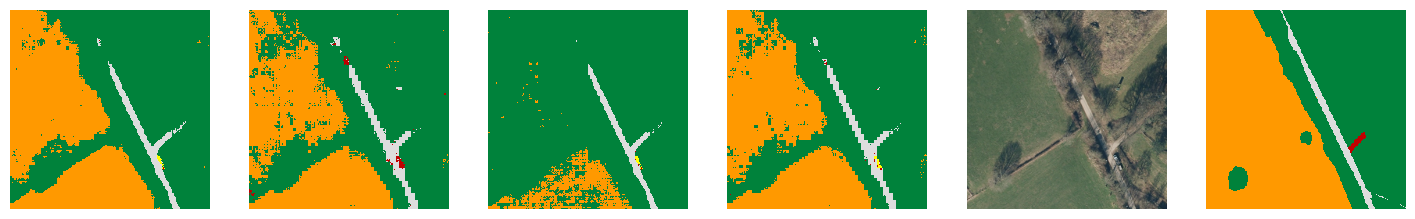

In [55]:
N = openearthmap_show_images(pdir3, index=0, eps=[49, 59])

## 4. w adaptor and fine-tuned dofa

(1359, 256, 256)
EP=49
EP=59
49-ts_masks-9        ['0.881677', '0.722372', '0.209705', '0.377032', '0.705304', '0.399224', '0.789875', '0.393508', '0.803306'] 0.5868893117865814
49-ts_masks-10       ['0.881677', '0.722372', '0.209705', '0.377032', '0.705304', '0.399224', '0.789875', '0.393508', '0.803306', '0.255031'] 0.5537034604764046
49-ts_masks_aux-9    ['0.867905', '0.717819', '0.090839', '0.380471', '0.677585', '0.401865', '0.750710', '0.387807', '0.762337'] 0.5597041709822231
49-ts_masks_aux-10   ['0.867905', '0.717819', '0.090839', '0.380471', '0.677585', '0.401865', '0.750710', '0.387807', '0.762337', '0.179580'] 0.5216917050023723
59-ts_masks-9        ['0.881521', '0.725082', '0.161773', '0.369428', '0.656065', '0.373536', '0.797398', '0.341361', '0.812888'] 0.5687835282332581
59-ts_masks-10       ['0.881521', '0.725082', '0.161773', '0.369428', '0.656065', '0.373536', '0.797398', '0.341361', '0.812888', '0.292327'] 0.541137888853575
59-ts_masks_aux-9    ['0.871215', '0.68140

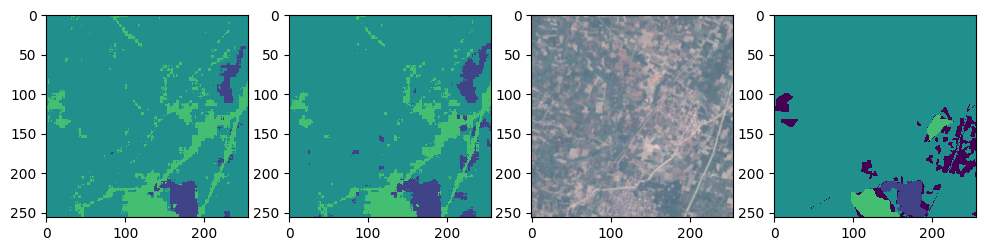

In [21]:
pdir4 = '/p/project1/hai_ws4eo/liu_ch/Weak_FT/segment-anything-2/Results_1st_stage_sub/FT_dofabA_aux_exact_sub_max1500_deI_mcloss/10F_1D_lr1e4_cos_w5_cos95/seed_42_bs_6'
N = dw_show_images(pdir4, index=0, eps=[49, 59])
ious_dw = dw_get_ious(pdir4, N, eps=[49, 59])

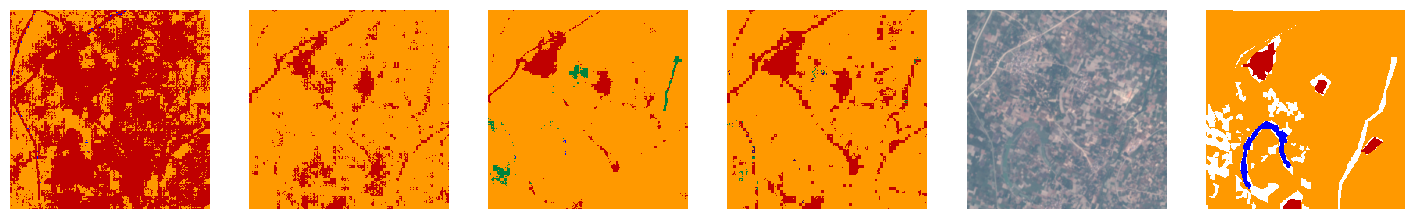

In [9]:
pdir4 = '/p/project1/hai_ws4eo/liu_ch/Weak_FT/segment-anything-2/Results_1st_stage_sub/FT_dofabA_aux_exact_sub_max1500_deI_mcloss/10F_1D_lr1e4_cos_w5_cos95/seed_42_bs_6'
N = dw_show_images(pdir4, index=1, eps=[29, 59])

[2 3 4 5 8]
(4275, 256, 256)
EP=49
EP=59
49-ts_masks          ['0.273233', '0.505676', '0.461680', '0.500488', '0.681311', '0.645482', '0.686244', '0.736663'] 0.5613471371779242
49-ts_masks_aux      ['0.255437', '0.499144', '0.463793', '0.446240', '0.668000', '0.616234', '0.675727', '0.712325'] 0.5421125948388383
59-ts_masks          ['0.223439', '0.521622', '0.476791', '0.498238', '0.679798', '0.673194', '0.684453', '0.740570'] 0.5622629377586628
59-ts_masks_aux      ['0.253294', '0.496328', '0.469611', '0.434180', '0.672986', '0.623982', '0.687391', '0.722565'] 0.5450421937510666


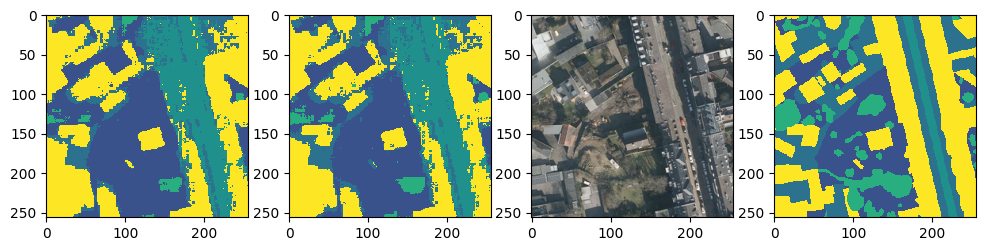

In [23]:
N = openearthmap_show_images(pdir4, index=10, eps=[49, 59])
ious_oem = openearthmap_get_ious(pdir4, N, eps=[49, 59])

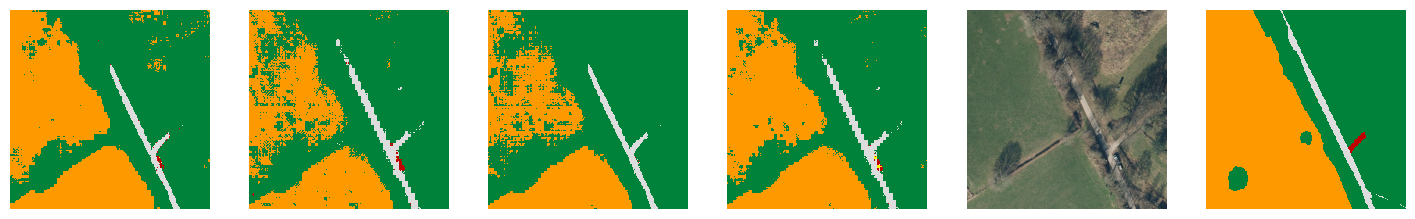

In [56]:
N = openearthmap_show_images(pdir4, index=0, eps=[49, 59])

# 5. adaptor scale=4, + 2 more dofa layers

(1359, 256, 256)
EP=49
EP=59
49-ts_masks-9        ['0.870732', '0.706549', '0.263133', '0.417979', '0.703140', '0.385006', '0.793498', '0.402613', '0.803865'] 0.5940571799005034
49-ts_masks-10       ['0.870732', '0.706549', '0.263133', '0.417979', '0.703140', '0.385006', '0.793498', '0.402613', '0.803865', '0.309312'] 0.5655826180814737
49-ts_masks_aux-9    ['0.861375', '0.709287', '0.234446', '0.374529', '0.700951', '0.400809', '0.781106', '0.405930', '0.810225'] 0.5865175770999146
49-ts_masks_aux-10   ['0.861375', '0.709287', '0.234446', '0.374529', '0.700951', '0.400809', '0.781106', '0.405930', '0.810225', '0.357404'] 0.5636061725732429
59-ts_masks-9        ['0.873718', '0.687002', '0.216478', '0.416016', '0.673099', '0.379834', '0.787727', '0.394056', '0.828926'] 0.5840951728162624
59-ts_masks-10       ['0.873718', '0.687002', '0.216478', '0.416016', '0.673099', '0.379834', '0.787727', '0.394056', '0.828926', '0.337700'] 0.5594556215687032
59-ts_masks_aux-9    ['0.861349', '0.6701

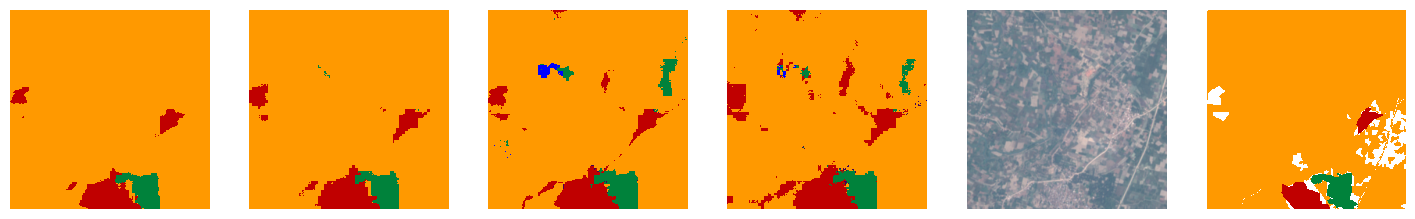

In [14]:
pdir5 = '/p/project1/hai_ws4eo/liu_ch/Weak_FT/segment-anything-2/Results_1st_stage_sub_s4/FT_dofab_aux_exact_sub_max1500_deI_mcloss/10F_1D_lr1e4_cos_w5_cos95/seed_42_bs_6'
N = dw_show_images(pdir5, index=0, eps=[49, 59])
ious_dw = dw_get_ious(pdir5, N, eps=[49, 59])

1359

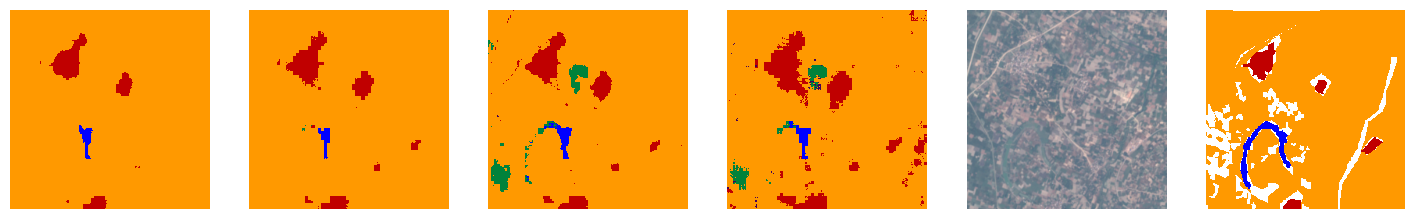

In [34]:
dw_show_images(pdir5, index=1, eps=[49, 59])

(4275, 256, 256)
EP=49
EP=59
49-ts_masks          ['0.312291', '0.544257', '0.508942', '0.548556', '0.707047', '0.687373', '0.722621', '0.754295'] 0.5981726090912127
49-ts_masks_aux      ['0.324223', '0.537193', '0.505808', '0.529272', '0.700002', '0.671045', '0.724089', '0.743551'] 0.5918979613042291
59-ts_masks          ['0.268170', '0.553795', '0.517719', '0.556638', '0.705961', '0.672278', '0.716444', '0.767839'] 0.5948557232381038
59-ts_masks_aux      ['0.301766', '0.546106', '0.513324', '0.533142', '0.700111', '0.651485', '0.720851', '0.757939'] 0.590590532847215


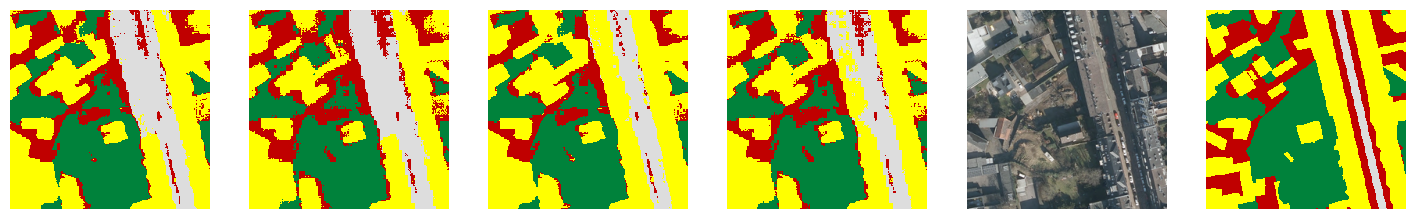

In [15]:
N = openearthmap_show_images(pdir5, index=10, eps=[49, 59])
ious_oem = openearthmap_get_ious(pdir5, N, eps=[49, 59])

# 6. scale=4, +FAM, initialize one decoder

(1359, 256, 256)
EP=49
EP=59
49-ts_masks-9        ['0.868259', '0.714412', '0.164756', '0.385759', '0.682184', '0.407206', '0.781096', '0.423538', '0.803158'] 0.5811520822599011
49-ts_masks-10       ['0.868259', '0.714412', '0.164756', '0.385759', '0.682184', '0.407206', '0.781096', '0.423538', '0.803158', '0.323021'] 0.5553389559765891
49-ts_masks_aux-9    ['0.869862', '0.710917', '0.178225', '0.376965', '0.649855', '0.407010', '0.756920', '0.396463', '0.734697'] 0.5645458654973818
49-ts_masks_aux-10   ['0.869862', '0.710917', '0.178225', '0.376965', '0.649855', '0.407010', '0.756920', '0.396463', '0.734697', '0.344985'] 0.5425897315236494
59-ts_masks-9        ['0.882057', '0.718011', '0.211700', '0.432246', '0.705563', '0.411030', '0.794630', '0.392180', '0.775620'] 0.5914484294149237
59-ts_masks-10       ['0.882057', '0.718011', '0.211700', '0.432246', '0.705563', '0.411030', '0.794630', '0.392180', '0.775620', '0.353722'] 0.5676758041143283
59-ts_masks_aux-9    ['0.869908', '0.7160

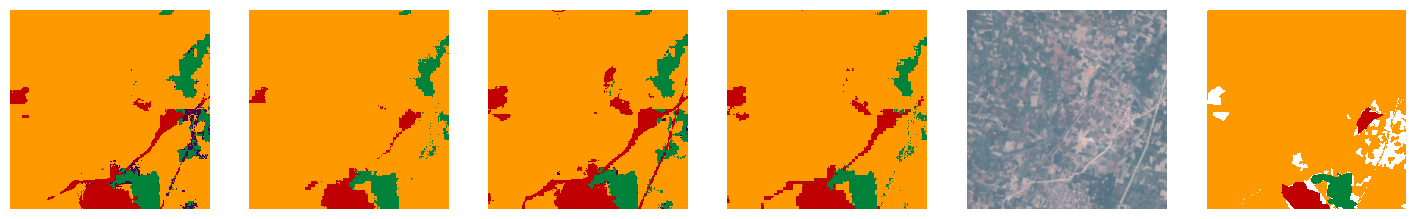

In [16]:
pdir6 = '/p/project1/hai_ws4eo/liu_ch/Weak_FT/segment-anything-2/Results_1st_stage_sub_s4/FT_dofab_aux_att_exact_sub_max1500_deI_mcloss/10F_1D_lr1e4_cos_w5_cos95/seed_42_bs_6'
N = dw_show_images(pdir6, index=0, eps=[49, 59])
ious_dw = dw_get_ious(pdir6, N, eps=[49, 59])

In [ ]:
N = openearthmap_show_images(pdir6, index=10, eps=[49, 59])
ious_oem = openearthmap_get_ious(pdir6, N, eps=[49, 59])

# 7. scale=4, +FAM, initialize two decoders

(1359, 256, 256)
EP=49
EP=59
49-ts_masks-9        ['0.850729', '0.646722', '0.229019', '0.370660', '0.724627', '0.375815', '0.802433', '0.424568', '0.718202'] 0.5714195642537244
49-ts_masks-10       ['0.850729', '0.646722', '0.229019', '0.370660', '0.724627', '0.375815', '0.802433', '0.424568', '0.718202', '0.247792'] 0.5390568433262284
49-ts_masks_aux-9    ['0.880364', '0.704738', '0.220179', '0.422569', '0.727260', '0.406912', '0.792233', '0.432624', '0.759298'] 0.5940196046138609
49-ts_masks_aux-10   ['0.880364', '0.704738', '0.220179', '0.422569', '0.727260', '0.406912', '0.792233', '0.432624', '0.759298', '0.281286'] 0.5627462027380308
59-ts_masks-9        ['0.868319', '0.705221', '0.220732', '0.380628', '0.682582', '0.371007', '0.793200', '0.439493', '0.803843'] 0.5850027023993675
59-ts_masks-10       ['0.868319', '0.705221', '0.220732', '0.380628', '0.682582', '0.371007', '0.793200', '0.439493', '0.803843', '0.345902'] 0.5610926751245013
59-ts_masks_aux-9    ['0.884178', '0.7036

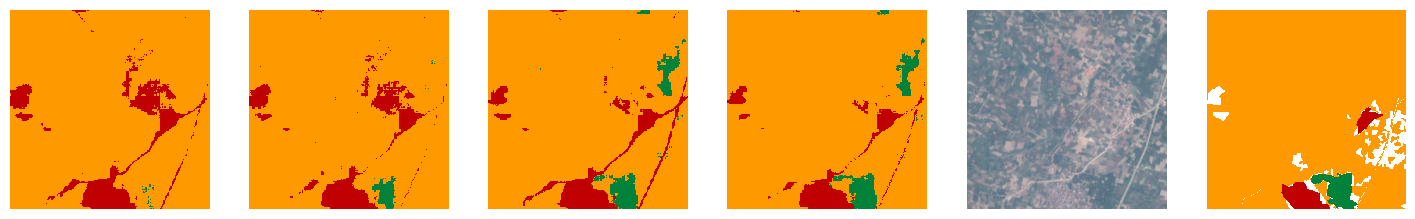

In [17]:
pdir7 = '/p/project1/hai_ws4eo/liu_ch/Weak_FT/segment-anything-2/Results_1st_stage_sub_s4/FT_dofab_aux_att_exact_sub_max1500_deIaux_mcloss/10F_1D_lr1e4_cos_w5_cos95/seed_42_bs_6'
N = dw_show_images(pdir7, index=0, eps=[49, 59])
ious_dw = dw_get_ious(pdir7, N, eps=[49, 59])

1359

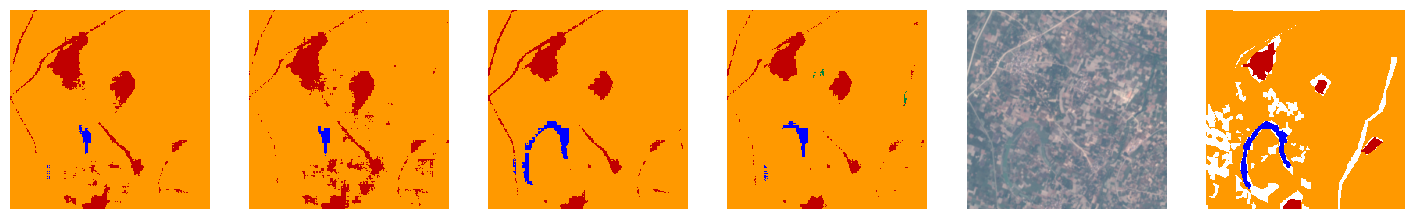

In [33]:
dw_show_images(pdir7, index=1, eps=[49, 59])

(4275, 256, 256)
EP=49
EP=59
49-ts_masks          ['0.349808', '0.534557', '0.505381', '0.538312', '0.700923', '0.656584', '0.721797', '0.759697'] 0.5958822539455624
49-ts_masks_aux      ['0.313962', '0.541095', '0.505184', '0.531788', '0.698948', '0.667833', '0.726196', '0.752496'] 0.5921878165071732
59-ts_masks          ['0.319768', '0.536021', '0.515592', '0.537208', '0.703356', '0.664355', '0.733161', '0.768283'] 0.5972179263582316
59-ts_masks_aux      ['0.327272', '0.542493', '0.516963', '0.527116', '0.702977', '0.668988', '0.737001', '0.764278'] 0.5983859607230776


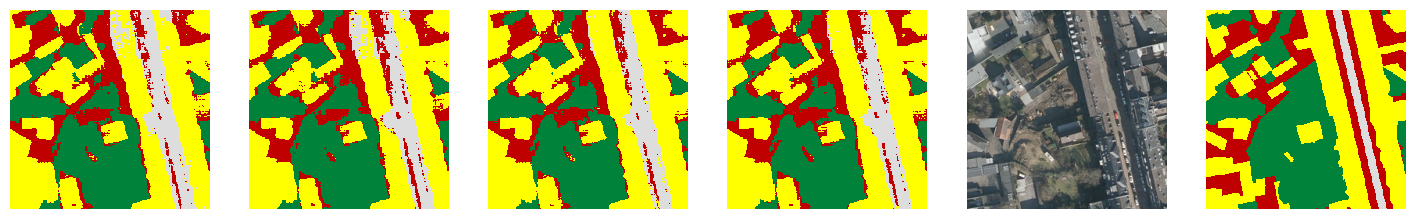

In [18]:
N = openearthmap_show_images(pdir7, index=10, eps=[49, 59])
ious_oem = openearthmap_get_ious(pdir7, N, eps=[49, 59])

# 8. scale=4, +FAM&PAM, initialize one decoder

(1359, 256, 256)
EP=49
EP=59
49-ts_masks-9        ['0.888055', '0.715802', '0.202278', '0.397366', '0.675218', '0.399681', '0.777297', '0.388186', '0.765858'] 0.5788599388851192
49-ts_masks-10       ['0.888055', '0.715802', '0.202278', '0.397366', '0.675218', '0.399681', '0.777297', '0.388186', '0.765858', '0.355806'] 0.5565545071566568
49-ts_masks_aux-9    ['0.874423', '0.708753', '0.192494', '0.356883', '0.658207', '0.400807', '0.764180', '0.404258', '0.738137'] 0.5664603540172825
49-ts_masks_aux-10   ['0.874423', '0.708753', '0.192494', '0.356883', '0.658207', '0.400807', '0.764180', '0.404258', '0.738137', '0.272010'] 0.5370152795598668
59-ts_masks-9        ['0.878064', '0.700044', '0.204068', '0.406491', '0.704528', '0.386757', '0.793456', '0.389298', '0.761242'] 0.5804385903041201
59-ts_masks-10       ['0.878064', '0.700044', '0.204068', '0.406491', '0.704528', '0.386757', '0.793456', '0.389298', '0.761242', '0.353348'] 0.5577295217297285
59-ts_masks_aux-9    ['0.862923', '0.7019

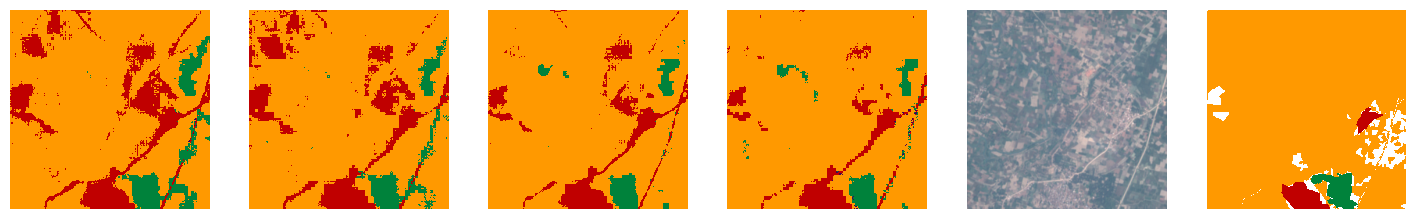

In [19]:
pdir8 = '/p/project1/hai_ws4eo/liu_ch/Weak_FT/segment-anything-2/Results_1st_stage_sub_s4/FT_dofab_aux_attcp_exact_sub_max1500_deI_mcloss/10F_1D_lr1e4_cos_w5_cos95/seed_42_bs_6'
N = dw_show_images(pdir8, index=0, eps=[49, 59])
ious_dw = dw_get_ious(pdir8, N, eps=[49, 59])

1359

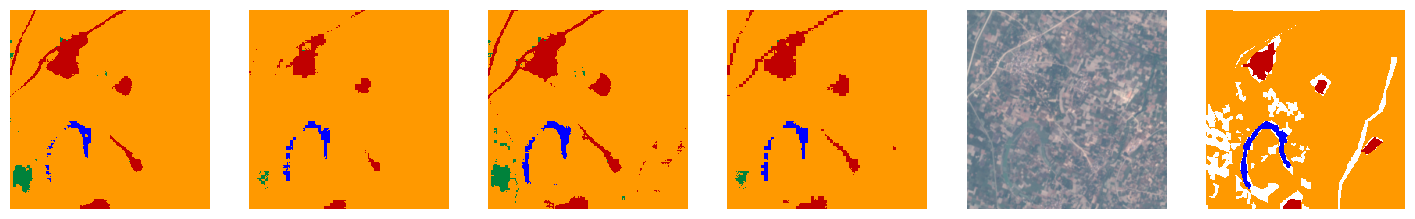

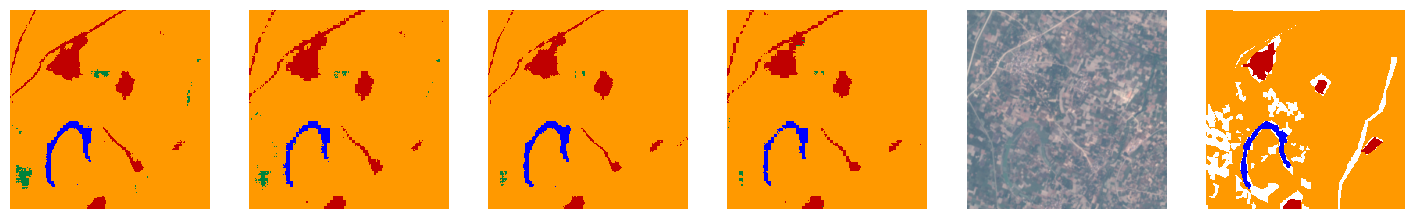

In [32]:
i = 1
dw_show_images(pdir6, index=i, eps=[49, 59])
dw_show_images(pdir8, index=i, eps=[49, 59])

(4275, 256, 256)
EP=49
EP=59
49-ts_masks          ['0.279897', '0.533350', '0.508848', '0.544287', '0.702100', '0.674961', '0.725676', '0.764804'] 0.5917402746253266
49-ts_masks_aux      ['0.261115', '0.538147', '0.500295', '0.532083', '0.695103', '0.655801', '0.727527', '0.758188'] 0.5835324518311087
59-ts_masks          ['0.238419', '0.527395', '0.510880', '0.559540', '0.701161', '0.689431', '0.717367', '0.769441'] 0.5892041963318367
59-ts_masks_aux      ['0.214905', '0.525383', '0.495525', '0.554907', '0.696786', '0.681690', '0.726388', '0.759195'] 0.5818472869182314


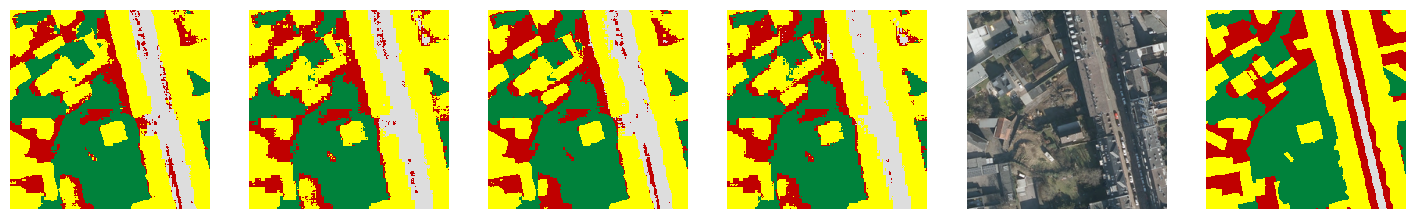

In [20]:
N = openearthmap_show_images(pdir8, index=10, eps=[49, 59])
ious_oem = openearthmap_get_ious(pdir8, N, eps=[49, 59])

# ALL

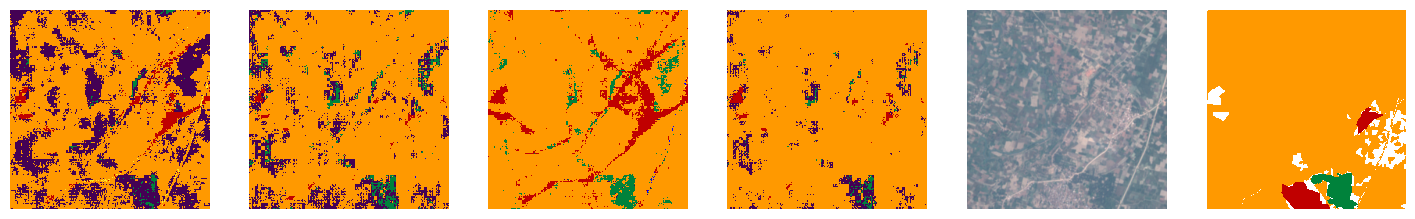

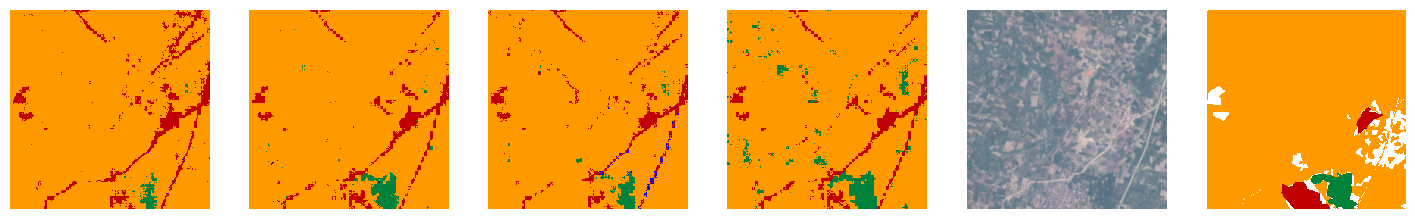

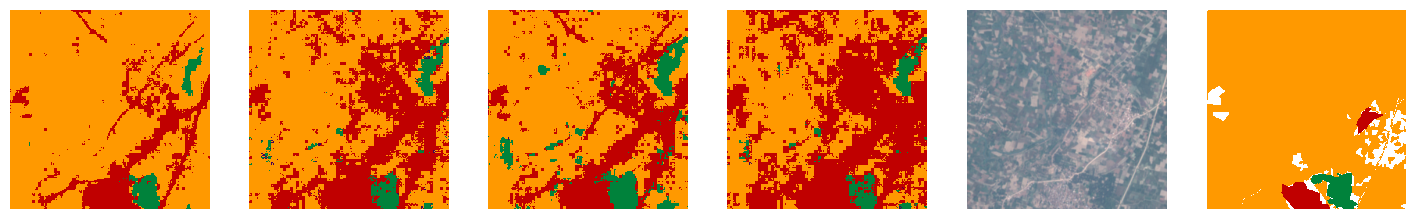

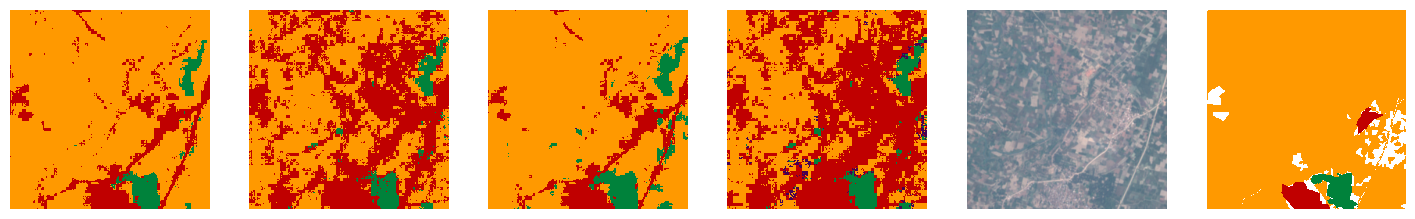

In [96]:
i = 0
_ = dw_show_images(pdir1, index=i, eps=[49, 59])
_ = dw_show_images(pdir2, index=i, eps=[49, 59])
_ = dw_show_images(pdir3, index=i, eps=[49, 59])
_ = dw_show_images(pdir4, index=i, eps=[49, 59])

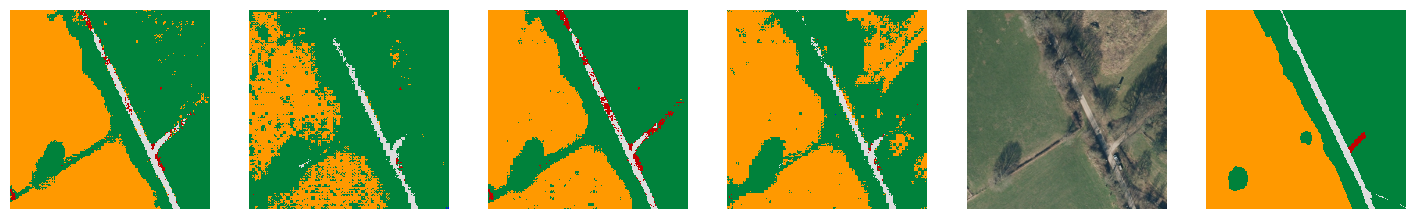

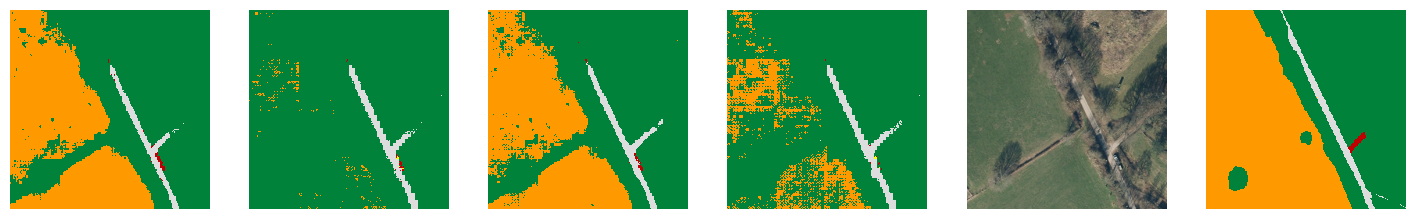

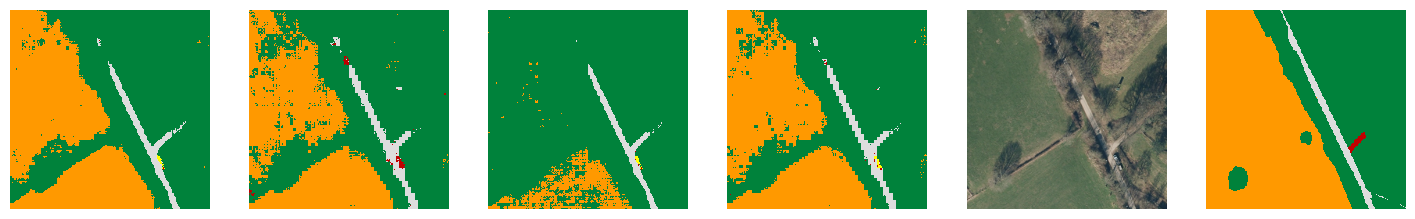

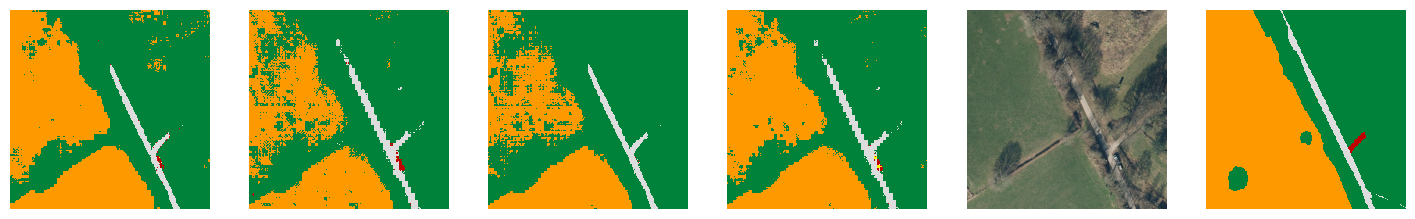

In [95]:
i = 0
_ = openearthmap_show_images(pdir1, index=i, eps=[49, 59])
_ = openearthmap_show_images(pdir2, index=i, eps=[49, 59])
_ = openearthmap_show_images(pdir3, index=i, eps=[49, 59])
_ = openearthmap_show_images(pdir4, index=i, eps=[49, 59])

In [33]:
fp3 = os.path.join(pdir3, 'checkpoints/epoch=59-step=8460.ckpt')
fp4 = '/p/project1/hai_ws4eo/liu_ch/Weak_FT/segment-anything-2/Results_1st_stage_sub/FT_dofabA_aux_exact_sub_max1500_deI_mcloss/10F_1D_lr1e4_cos_w5_cos95/seed_42_bs_6/checkpoints/epoch=29-step=4230.ckpt'
a3 = torch.load(fp3, map_location='cpu')['state_dict']
a4 = torch.load(fp4, map_location='cpu')['state_dict']
# for k in a3.keys(): print(k)

ks  = []
for k in a3.keys():
    if 'model.image_encoder.trunk.prompt_generator.dofa' in k: 
        print(k)
        ks.append(k)

FileNotFoundError: [Errno 2] No such file or directory: '/p/project1/hai_ws4eo/liu_ch/Weak_FT/segment-anything-2/Results_1st_stage_sub/FT_dofabA_aux_exact_sub_max1500_deI_mcloss/10F_1D_lr1e4_cos_w5_cos95/seed_42_bs_6/checkpoints/epoch=29-step=4230.ckpt'

In [34]:
for k in ks:
    a = torch.max(a3[k]-a4[k])
    print(k, a)

model.image_encoder.trunk.prompt_generator.dofa.cls_token tensor(0.0801)
model.image_encoder.trunk.prompt_generator.dofa.pos_embed tensor(0.)
model.image_encoder.trunk.prompt_generator.dofa.patch_embed.weight_generator.weight_tokens tensor(0.0117)
model.image_encoder.trunk.prompt_generator.dofa.patch_embed.weight_generator.bias_token tensor(0.0065)
model.image_encoder.trunk.prompt_generator.dofa.patch_embed.weight_generator.transformer_encoder.layers.0.self_attn.in_proj_weight tensor(0.0394)
model.image_encoder.trunk.prompt_generator.dofa.patch_embed.weight_generator.transformer_encoder.layers.0.self_attn.in_proj_bias tensor(0.0153)
model.image_encoder.trunk.prompt_generator.dofa.patch_embed.weight_generator.transformer_encoder.layers.0.self_attn.out_proj.weight tensor(0.0247)
model.image_encoder.trunk.prompt_generator.dofa.patch_embed.weight_generator.transformer_encoder.layers.0.self_attn.out_proj.bias tensor(0.0083)
model.image_encoder.trunk.prompt_generator.dofa.patch_embed.weight_